


# 09. Solar model

**Part 1. Analysis**
1. Solar power over the day, one curve per day

**Part 2. Model**
2. Basic solar model: one sinusoid over the day, then the final parameters

**Part 3. Prediction**
3. The fixed model (same curve every day) compared with the measured solar power

**Part 3b. A better model: one smooth curve per day**
3b. Same smooth shape every day, but each day gets its own peak; compared with the fixed model

**Part 4. Irradiance → power**
4. Convert irradiance (W/m², e.g. from a weather forecast) into solar power (W)

battery3 = solar. Solar only comes over Starlink (`direct`), so there's only data while Starlink is on (14 Jul 07:43 to 27 Jul 02:05).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (14, 6), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a    # W, solar in
df["day"] = df.t.dt.floor("D")
df["hour"] = (df.t - df.day).dt.total_seconds() / 3600           # hour of day, UTC
solar = df.dropna(subset=["P_solar"])

def daily_axis(ax, start=pd.Timestamp("2025-07-14", tz="UTC"), end=pd.Timestamp("2025-07-28", tz="UTC")):
    ax.set_xlim(start, end)
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
solar.groupby(solar.day.dt.strftime("%d %b")).P_solar.agg(["size", "min", "median", "max"]).round(1)

,size,min,median,max
day,,,,
14 Jul,9775,0.0,79.9,226.6
15 Jul,1574,0.0,120.3,205.9
16 Jul,1594,0.0,22.6,256.7
17 Jul,572,0.0,16.8,90.6
18 Jul,609,0.0,50.6,221.7
19 Jul,583,0.0,44.8,178.9
20 Jul,856,0.0,19.9,170.0
21 Jul,658,0.0,15.6,127.0
22 Jul,766,0.0,34.7,195.6


# Part 1. Analysis

## 1. Solar power over the day, every day on one plot

X = hour of day (UTC), y = solar power (V × I on battery3). One colour per day, from early (dark) to late (yellow). Every row with a solar value is plotted. Lines are broken wherever there's more than 5 min between rows (Starlink off), so they never bridge a gap.

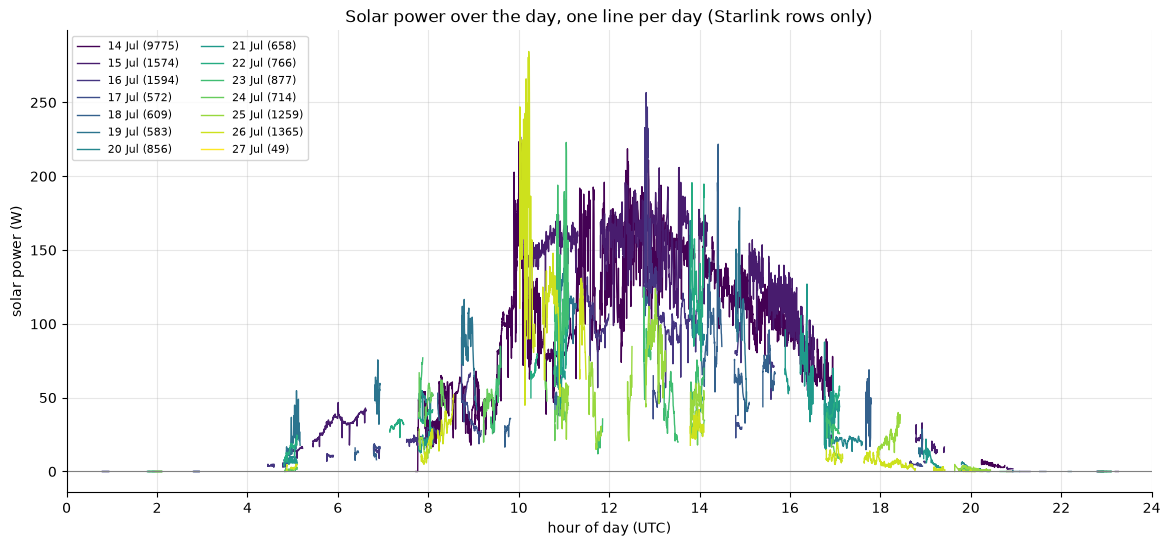

In [2]:
days = sorted(solar.day.unique())
colors = plt.cm.viridis(np.linspace(0, 1, len(days)))
fig, ax = plt.subplots()
for day, color in zip(days, colors):
    d = solar[solar.day == day]
    gap = np.flatnonzero((d.t.diff() > pd.Timedelta("5min")).values)
    x_b = np.insert(d.hour.values, gap, np.nan)       # a NaN before every gap breaks the line there
    y_b = np.insert(d.P_solar.values, gap, np.nan)
    ax.plot(x_b, y_b, "-", lw=1, color=color, label=f"{pd.Timestamp(day):%d %b} ({len(d)})")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 2))
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("solar power (W)")
ax.set_title("Solar power over the day, one line per day (Starlink rows only)")
ax.legend(loc="upper left", fontsize=8, ncol=2)
plt.show()

# Part 2. Model

## 2. Model: basic solar model: P(t) = A + B·cos(ωt) + C·sin(ωt)

t = hour of day (UTC), ω = 2π / 24 h. That's a sinusoid with a 24 h period. It's linear in A, B and C, so ordinary least squares solves it (`np.linalg.lstsq`).

The same curve can be written as **P(t) = A + R·cos(ω(t − t_peak))**, with amplitude R = √(B² + C²) and peak hour t_peak = atan2(C, B) / ω. Those two are easier to read, so they're printed too.

**One point per minute:** Starlink sent every 1 s on 14 Jul and every 15 s on other days, so 14 Jul has about half of all solar rows. Fitting raw rows would mostly fit 14 Jul. Instead, solar power is averaged per minute and each minute counts once. All minutes are kept, day and night, every day.

,value,std error
A (W),35.70,0.74
B (W),-67.06,1.02
C (W),-9.32,0.94


amplitude R = 67.7 W, peak at 12.53 h UTC, max = A + R = 103.4 W, min = A − R = -32.0 W
n = 2905 minutes, R² = 0.597, residual std = 34.7 W


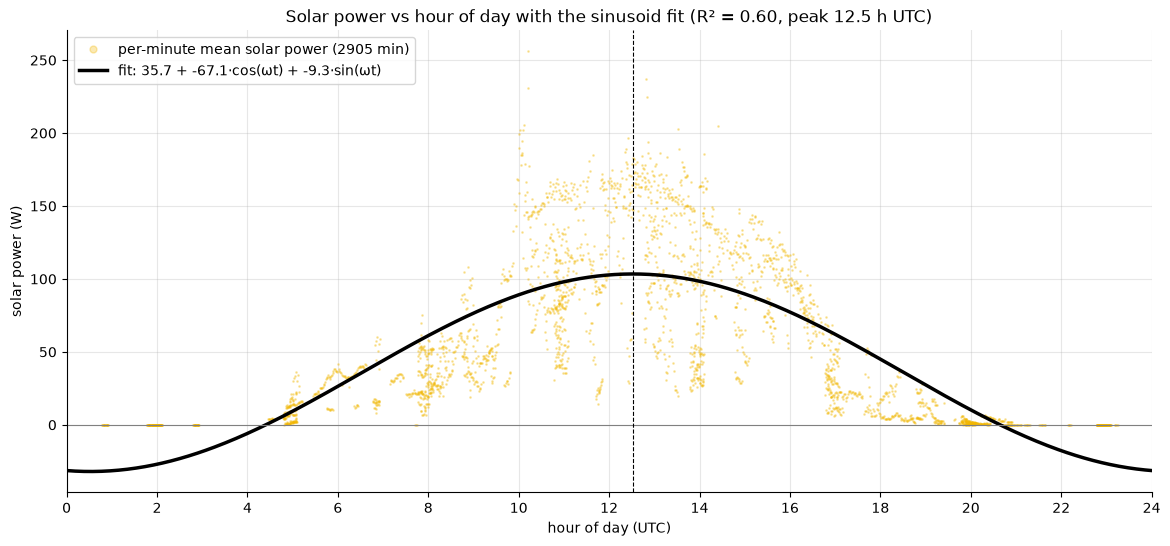

In [3]:
OMEGA = 2 * np.pi / 24
sm = solar.set_index("t").P_solar.resample("1min").mean().dropna().to_frame()
sm["hour"] = (sm.index - sm.index.floor("D")).total_seconds() / 3600

X = np.column_stack([np.ones(len(sm)), np.cos(OMEGA * sm.hour), np.sin(OMEGA * sm.hour)])
y = sm.P_solar.values
coef, *_ = np.linalg.lstsq(X, y, rcond=None)
resid = y - X @ coef
r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * (resid ** 2).sum() / (len(y) - X.shape[1]))
A, B, C = coef
R = np.hypot(B, C)
t_peak = (np.arctan2(C, B) / OMEGA) % 24
display(pd.DataFrame({"value": coef, "std error": se}, index=["A (W)", "B (W)", "C (W)"]).round(2))
print(f"amplitude R = {R:.1f} W, peak at {t_peak:.2f} h UTC, max = A + R = {A + R:.1f} W, min = A − R = {A - R:.1f} W")
print(f"n = {len(y)} minutes, R² = {r2:.3f}, residual std = {resid.std():.1f} W")

fig, ax = plt.subplots()
ax.plot(sm.hour, sm.P_solar, ".", ms=2, alpha=0.3, color="#f2b701", label=f"per-minute mean solar power ({len(sm)} min)")
h = np.linspace(0, 24, 500)
ax.plot(h, A + B * np.cos(OMEGA * h) + C * np.sin(OMEGA * h), lw=2.5, color="k",
        label=f"fit: {A:.1f} + {B:.1f}·cos(ωt) + {C:.1f}·sin(ωt)")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(t_peak, color="k", lw=0.8, ls="--")
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 2))
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("solar power (W)")
ax.set_title(f"Solar power vs hour of day with the sinusoid fit (R² = {r2:.2f}, peak {t_peak:.1f} h UTC)")
ax.legend(markerscale=5, loc="upper left")
plt.show()

### Final parameters

**P_solar(t) = max(0, A + B·cos(ωt) + C·sin(ωt))**, ω = 2π/24 h, t = UTC hour. Clipped at 0 because the raw curve goes negative at night; this clipped version is what nb 10 uses.

Known limits: the same curve every day (no clouds, no day-to-day change), a 24 h period for a ~16 h day, and it's an average over cloudy and clear minutes, not a clear-sky curve.

In [4]:
pd.DataFrame([
    ["A", f"{A:.1f} ± {se[0]:.1f} W", "mean level"],
    ["B", f"{B:.1f} ± {se[1]:.1f} W", "cos term"],
    ["C", f"{C:.1f} ± {se[2]:.1f} W", "sin term"],
    ["amplitude", f"{R:.1f} W", "√(B² + C²)"],
    ["peak", f"{t_peak:.2f} h UTC", "atan2(C, B) / ω"],
    ["fit", f"R² = {r2:.2f}, residual std ≈ {resid.std():.0f} W", f"{len(y)} per-minute means"],
], columns=["parameter", "value", "note"]).set_index("parameter")

,value,note
parameter,,
A,35.7 ± 0.7 W,mean level
B,-67.1 ± 1.0 W,cos term
C,-9.3 ± 0.9 W,sin term
amplitude,67.7 W,√(B² + C²)
peak,12.53 h UTC,"atan2(C, B) / ω"
fit,"R² = 0.60, residual std ≈ 35 W",2905 per-minute means


# Part 3. Prediction

## 3. Prediction: fixed model vs measured solar

The model only knows the time of day, so it predicts **the same curve every day**. It is compared with the measured solar power (per-minute mean, Starlink minutes only, the only ones with solar). Error = actual − predicted.

In [5]:
def solar_model(hour):
    return np.clip(A + B * np.cos(OMEGA * hour) + C * np.sin(OMEGA * hour), 0, None)

sp = sm.copy()
sp["P_pred"] = solar_model(sp.hour)
sp["err"] = sp.P_solar - sp.P_pred
print(f"n = {len(sp)} minutes: mean error {sp.err.mean():+.1f} W, RMSE {np.sqrt((sp.err ** 2).mean()):.1f} W, "
      f"max |error| {sp.err.abs().max():.0f} W")

n = 2905 minutes: mean error -2.4 W, RMSE 33.8 W, max |error| 165 W


**Over the mission.** Top: measured solar (yellow dots, one per minute) and the model as a continuous line (black, also through the hours with no Starlink). Bottom: error = actual − predicted, only where there's a measurement.

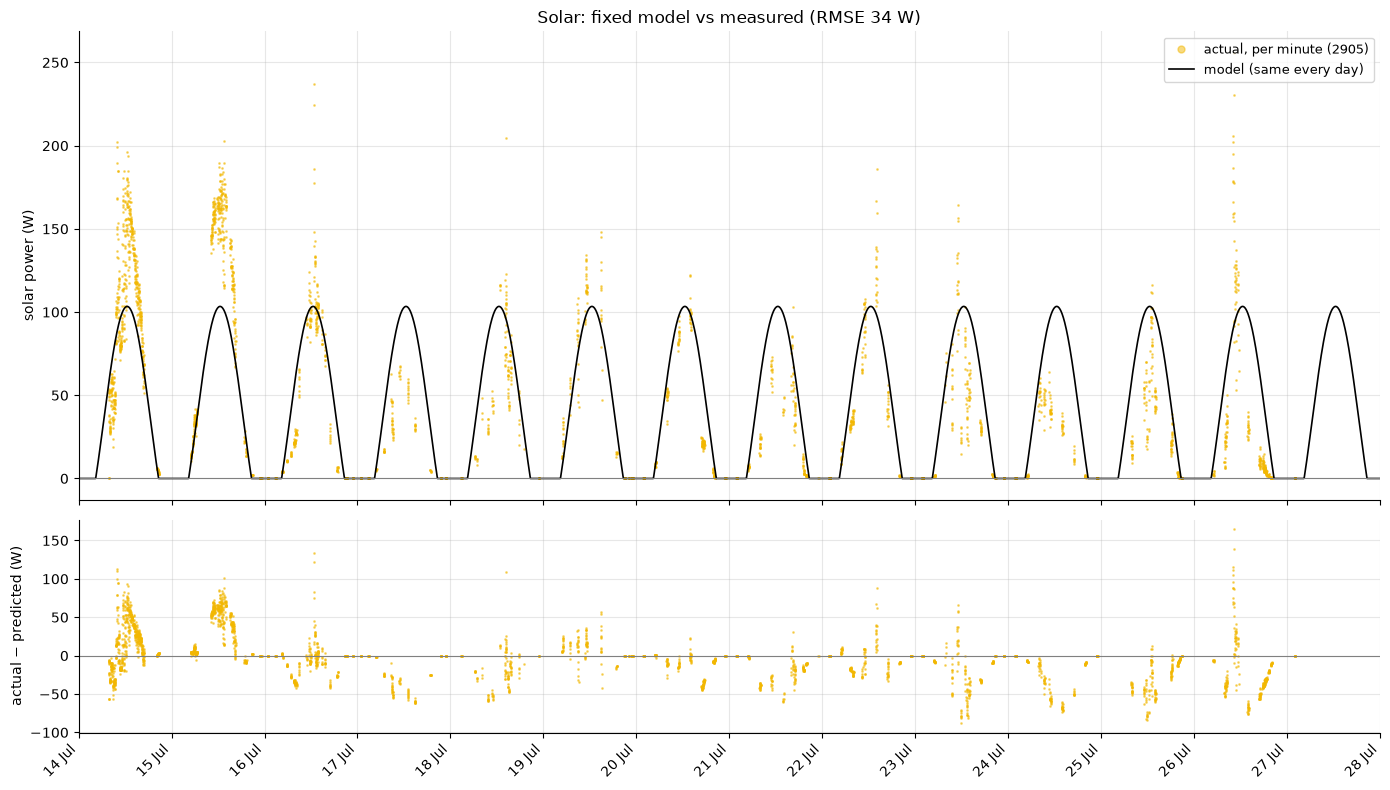

In [6]:
grid = pd.date_range("2025-07-14", "2025-07-28", freq="5min", tz="UTC")
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax.plot(sp.index, sp.P_solar, ".", ms=2, alpha=0.5, color="#f2b701", label=f"actual, per minute ({len(sp)})")
ax.plot(grid, solar_model((grid - grid.floor("D")).total_seconds() / 3600), "-", lw=1.2, color="k", label="model (same every day)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("solar power (W)")
ax.set_title(f"Solar: fixed model vs measured (RMSE {np.sqrt((sp.err ** 2).mean()):.0f} W)")
ax.legend(markerscale=5, loc="upper right", fontsize=9)
ax2.plot(sp.index, sp.err, ".", ms=2, alpha=0.5, color="#f2b701")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_ylabel("actual − predicted (W)")
daily_axis(ax2)
plt.tight_layout(); plt.show()

**Per day:** mean measured vs mean predicted solar over the minutes with data. Days with few minutes or minutes only at some hours are not comparable with each other.

In [7]:
g = sp.groupby(sp.index.floor("D"))
daily = g.agg(minutes=("err", "size"), actual_W=("P_solar", "mean"), predicted_W=("P_pred", "mean"), mean_error_W=("err", "mean"))
daily["RMSE_W"] = g.err.apply(lambda e: np.sqrt((e ** 2).mean()))
daily.set_axis(daily.index.strftime("%d %b")).round(1).T

t,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul
minutes,573.0,407.0,271.0,115.0,122.0,133.0,191.0,153.0,171.0,184.0,152.0,180.0,244.0,9.0
actual_W,98.6,106.1,55.2,22.5,56.0,56.0,30.5,26.5,43.1,36.6,21.8,32.8,37.5,0.0
predicted_W,83.5,70.5,62.7,47.8,74.4,48.1,43.9,45.6,48.1,56.6,47.5,60.5,58.9,0.0
mean_error_W,15.1,35.6,-7.5,-25.3,-18.4,7.9,-13.4,-19.1,-5.0,-20.0,-25.7,-27.7,-21.4,0.0
RMSE_W,35.0,44.8,23.4,33.5,30.5,17.3,20.5,25.5,18.8,34.9,35.8,35.7,44.1,0.0


# Part 3b. The pseudo-forecast: one smooth curve per day

The fixed model draws the same curve every day, so it can't follow sunny days (14–15 Jul) or cloudy ones (17, 24 Jul). Here every day keeps **the same smooth shape** but gets **its own peak**. We call this the **pseudo-forecast**: it's the model the forecast uses (nb 12), with the fitted daily peaks standing in for a weather forecast that came true (positions and dates are shifted, so no real forecast matches the days).


**P(t) = peak_day · shape(t)**, with **shape(t) = cos(π·(t − t_noon) / L)ᵖ** inside the day (|t − t_noon| < L/2) and **0 at night**.

- **t_noon** = hour of the peak (UTC), **L** = length of the solar day (h), **p** = how pointed the curve is (bigger p = narrower peak). These three are **shared by all days**.
- **peak_day** = one number per day: the height of that day's curve.

Fitting: for any (t_noon, L, p), each day's best peak has a closed form (least squares on one number: Σ y·s / Σ s²). So we search a grid of (t_noon, L, p) and keep the one with the smallest total error. Same per-minute means as section 2, so 14 Jul's 1 Hz rows don't dominate.

**Days with no daylight data** (27 Jul: Starlink stops at 02:05, and 28–30 Jul) get the **mean peak** of the other days.

In [8]:
import itertools

def shape(hour, t_noon, L, p):
    """Smooth daylight bump: cos^p inside the solar day, 0 at night. Peak = 1 at t_noon."""
    x = np.pi * (np.asarray(hour) - t_noon) / L
    return np.where(np.abs(x) < np.pi / 2, np.cos(np.clip(x, -np.pi / 2, np.pi / 2)) ** p, 0.0)

def daily_peaks(hour, y, day, t_noon, L, p):
    """Best peak per day for this shape (least squares on one number per day)."""
    s = shape(hour, t_noon, L, p)
    day = pd.DatetimeIndex(day)
    day = day.tz_localize("UTC") if day.tz is None else day
    g = pd.DataFrame({"day": day, "ys": y * s, "ss": s * s}).groupby("day").sum()
    return g.ys / g.ss.where(g.ss > 0), s

sm["day"] = sm.index.floor("D")
DAYLIGHT_MIN = 30                      # a day needs this many minutes with shape > 0.1 to get its own peak
best = None
for t_noon, L, p in itertools.product(np.arange(11.5, 13.51, 0.1), np.arange(14, 24.01, 0.5), np.arange(0.5, 8.01, 0.25)):
    pk, s = daily_peaks(sm.hour.values, sm.P_solar.values, sm.day.values, t_noon, L, p)
    sse = np.nansum((sm.P_solar.values - pk.reindex(sm.day).fillna(0).values * s) ** 2)
    if best is None or sse < best[0]:
        best = (sse, t_noon, L, p)
_, T_NOON, L_DAY, P_SHAPE = best

PEAKS, s = daily_peaks(sm.hour.values, sm.P_solar.values, sm.day.values, T_NOON, L_DAY, P_SHAPE)
n_day = pd.Series(s > 0.1, index=sm.index).groupby(sm.day).sum()
PEAKS = PEAKS.where(n_day >= DAYLIGHT_MIN)                       # too little daylight data -> unknown
PEAK_MEAN = PEAKS.mean()
half = np.arccos(0.02 ** (1 / P_SHAPE)) * L_DAY / np.pi      # hours from t_noon where the shape falls to 2 % of the peak
print(f"shape: t_noon = {T_NOON:.1f} h UTC, L = {L_DAY:.1f} h, p = {P_SHAPE:.2f} -> above 2 % of the peak from {T_NOON - half:.1f} to {T_NOON + half:.1f} h UTC")
print("(L sits at the top of the search grid, 24 h: with a large p the curve is bell-shaped and already ~0 at night, so a longer L wouldn't change it much)")
print(f"mean peak over days with data = {PEAK_MEAN:.0f} W")
pd.DataFrame({"daylight minutes": n_day.astype(int), "peak (W)": PEAKS.round(0)}).set_axis(PEAKS.index.strftime("%d %b")).T

shape: t_noon = 12.7 h UTC, L = 24.0 h, p = 5.50 -> above 2 % of the peak from 4.6 to 20.8 h UTC
(L sits at the top of the search grid, 24 h: with a large p the curve is bell-shaped and already ~0 at night, so a longer L wouldn't change it much)
mean peak over days with data = 100 W


day,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul
daylight minutes,544.0,318.0,204.0,72.0,110.0,79.0,108.0,97.0,105.0,112.0,83.0,129.0,205.0,0.0
peak (W),143.0,172.0,110.0,59.0,90.0,138.0,98.0,80.0,119.0,73.0,52.0,64.0,102.0,NaN


**The shape, and every day's curve.** Left: the shared shape (peak = 1) against the old sinusoid scaled to the same height. Right: each day's curve (colour = day, same order as section 1).

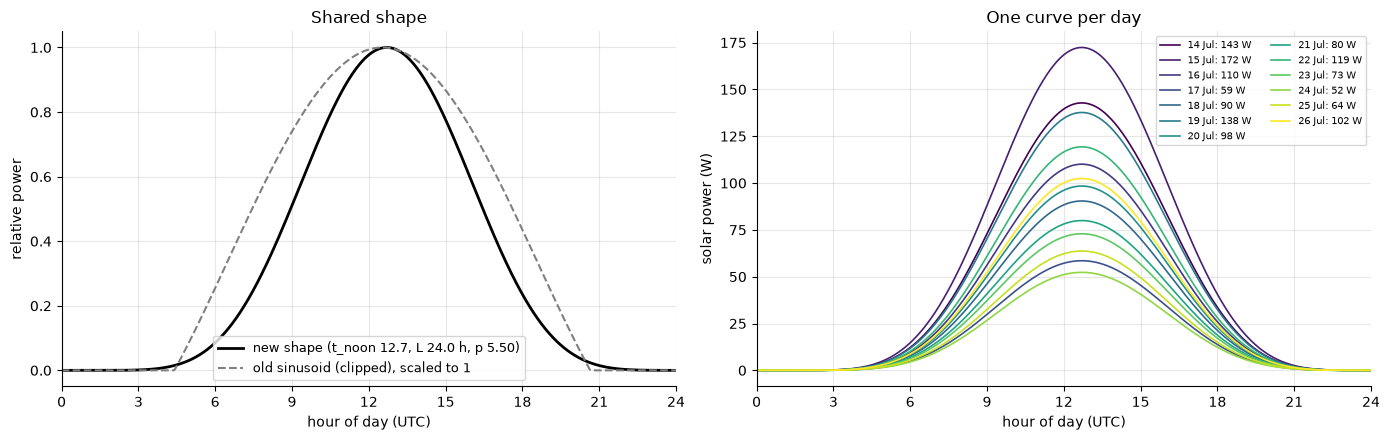

In [9]:
h = np.linspace(0, 24, 500)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
a1.plot(h, shape(h, T_NOON, L_DAY, P_SHAPE), color="k", lw=2, label=f"new shape (t_noon {T_NOON:.1f}, L {L_DAY:.1f} h, p {P_SHAPE:.2f})")
a1.plot(h, solar_model(h) / solar_model(h).max(), color="grey", ls="--", label="old sinusoid (clipped), scaled to 1")
a1.set_xlim(0, 24); a1.set_xticks(range(0, 25, 3)); a1.set_xlabel("hour of day (UTC)"); a1.set_ylabel("relative power")
a1.set_title("Shared shape"); a1.legend(fontsize=9)
pk_days = PEAKS.dropna()
for d, c in zip(pk_days.index, plt.cm.viridis(np.linspace(0, 1, len(pk_days)))):
    a2.plot(h, pk_days[d] * shape(h, T_NOON, L_DAY, P_SHAPE), color=c, lw=1.2, label=f"{d:%d %b}: {pk_days[d]:.0f} W")
a2.set_xlim(0, 24); a2.set_xticks(range(0, 25, 3)); a2.set_xlabel("hour of day (UTC)"); a2.set_ylabel("solar power (W)")
a2.set_title("One curve per day"); a2.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 3b. Prediction: one curve per day vs measured

Same comparison as section 3, now with the per-day curve. Each panel is one day: measured per-minute solar (yellow dots), the per-day curve (black) and the old fixed curve (grey dashed).

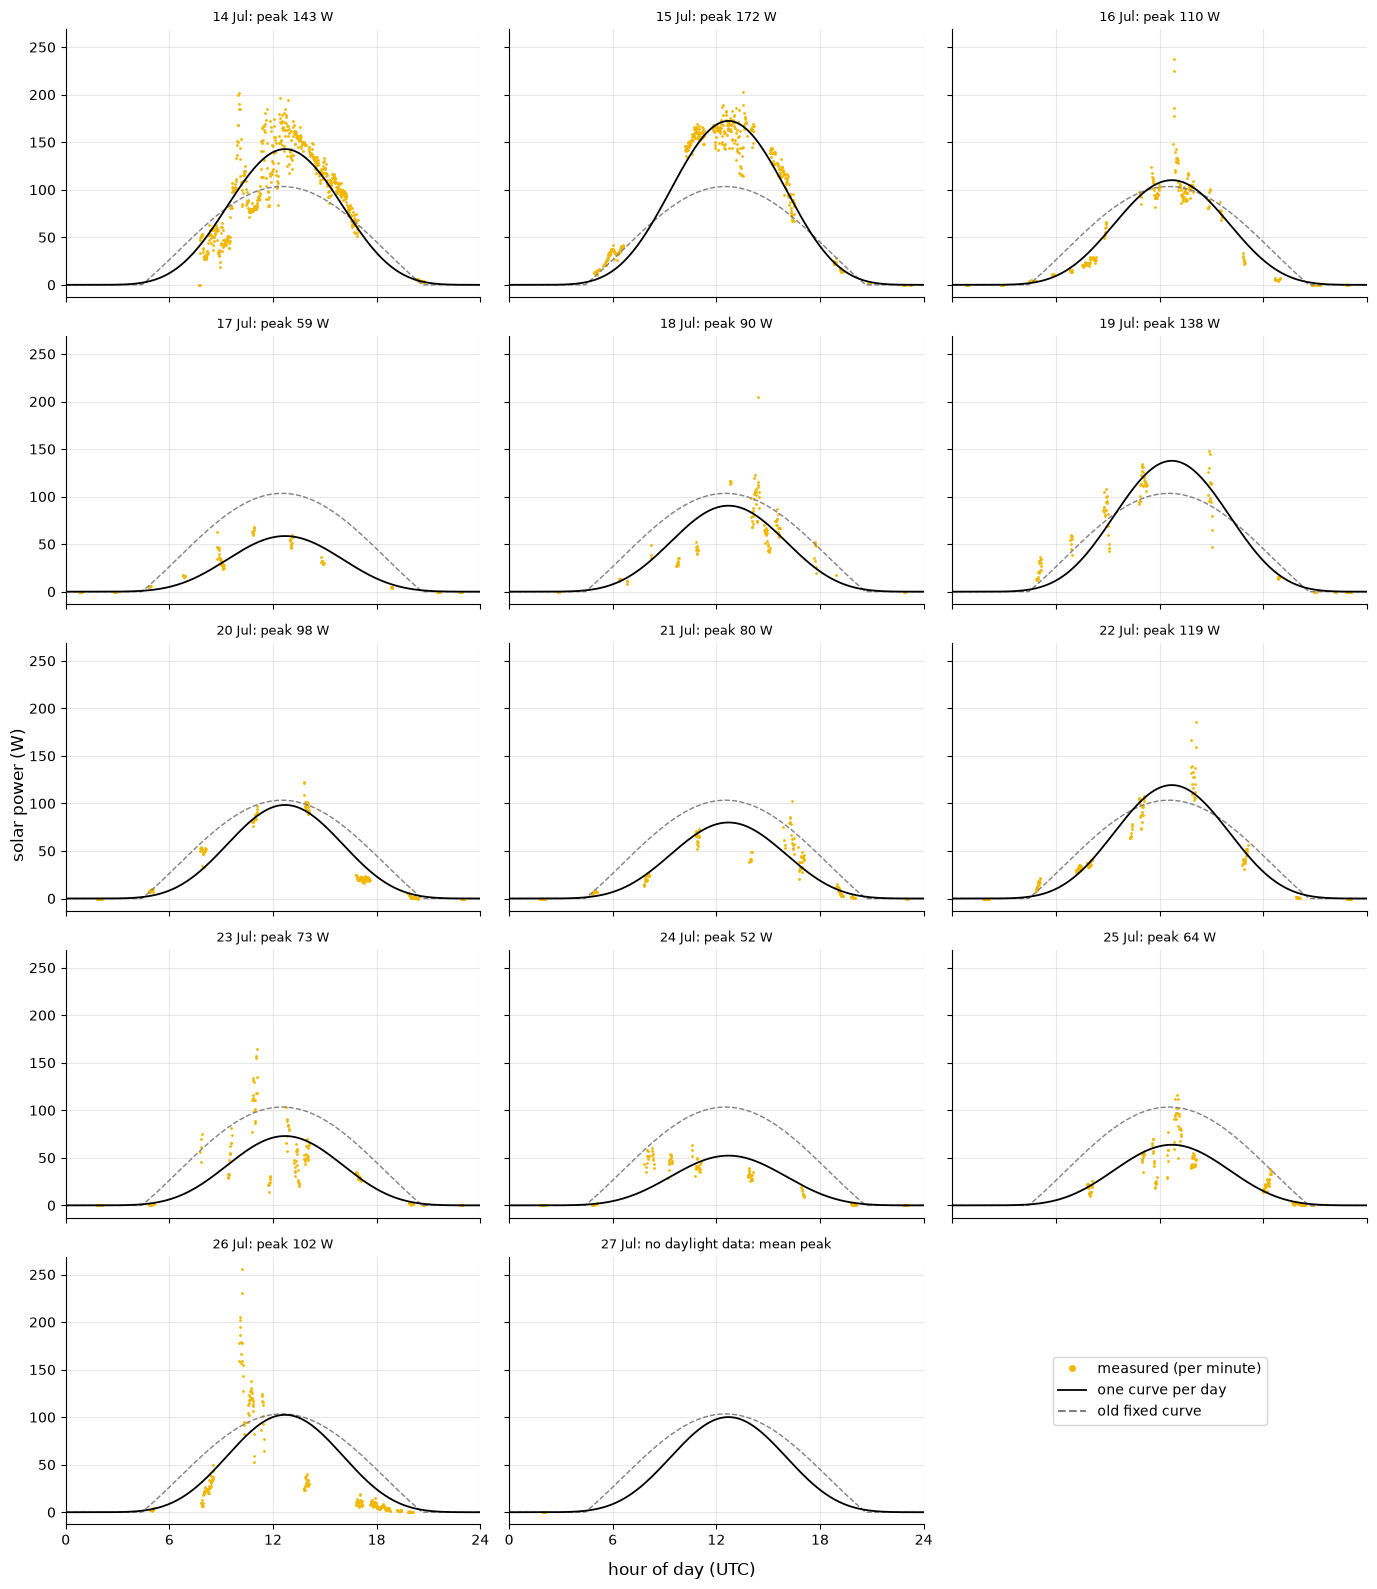

In [10]:
def solar_daily(t):
    """Per-day model at times t (DatetimeIndex). Days without a fitted peak use the mean peak."""
    t = pd.DatetimeIndex(t)
    pk = PEAKS.reindex(t.floor("D")).fillna(PEAK_MEAN).values
    return pk * shape((t - t.floor("D")).total_seconds() / 3600, T_NOON, L_DAY, P_SHAPE)

sp["P_daily"] = solar_daily(sp.index)
sp["err_daily"] = sp.P_solar - sp.P_daily

days_sp = sorted(sp.index.floor("D").unique())
fig, axes = plt.subplots(5, 3, figsize=(14, 16), sharex=True, sharey=True)
axes = axes.ravel()
for ax, d in zip(axes, days_sp):
    g = sp[sp.index.floor("D") == d]
    tt = pd.date_range(d, d + pd.Timedelta("1D"), freq="5min")
    hh = (tt - d).total_seconds() / 3600
    ax.plot(g.hour, g.P_solar, ".", ms=2, color="#f2b701")
    ax.plot(hh, solar_model(hh), "--", color="grey", lw=1)
    ax.plot(hh, solar_daily(tt), "-", color="k", lw=1.3)
    peak = f"peak {PEAKS[d]:.0f} W" if pd.notna(PEAKS.get(d)) else "no daylight data: mean peak"
    ax.set_title(f"{d:%d %b}: {peak}", fontsize=9)
    ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 6))
for ax in axes[len(days_sp):]:
    ax.axis("off")
from matplotlib.lines import Line2D
axes[len(days_sp)].legend(handles=[Line2D([], [], marker=".", ls="", color="#f2b701", ms=8, label="measured (per minute)"),
                                   Line2D([], [], color="k", lw=1.3, label="one curve per day"),
                                   Line2D([], [], color="grey", ls="--", label="old fixed curve")], loc="center")
fig.supxlabel("hour of day (UTC)"); fig.supylabel("solar power (W)")
plt.tight_layout(); plt.show()

### The full pseudo-forecast, 14–30 Jul

The model exactly as the forecast uses it (nb 10, nb 12): one continuous line over the whole deployment, the day's curve joined at midnight (it's ~0 at night, so the joins don't show). Measured solar (per-minute means, Starlink only) as yellow dots on top. **Grey band: no fitted peak** (27 Jul onwards, Starlink stopped), so those days use the **mean peak** of the others. The number above each day is its peak (W). Bottom: error = actual − pseudo-forecast, where there's a measurement.

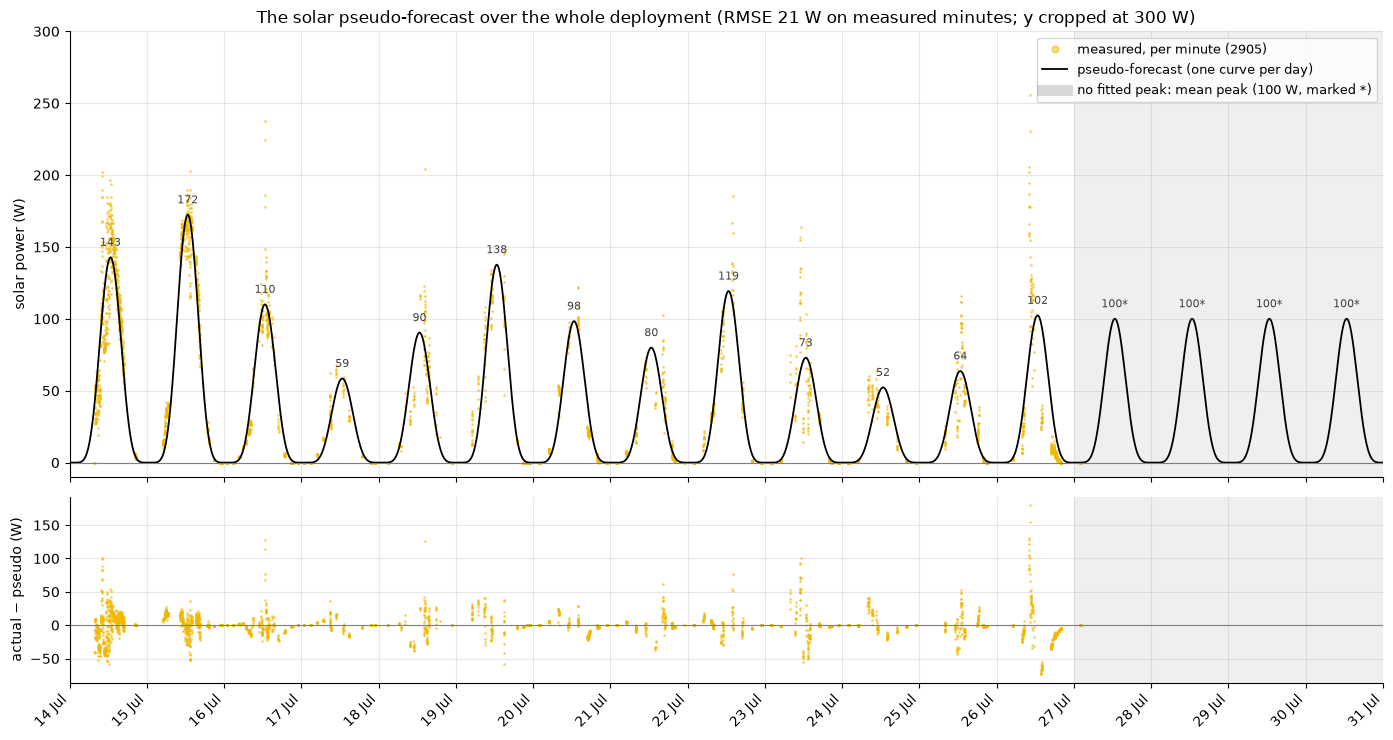

In [11]:
full_t = pd.date_range("2025-07-14", "2025-07-31", freq="5min", tz="UTC", inclusive="left")
full_p = solar_daily(full_t)
no_peak = PEAKS.index[PEAKS.isna()].min() if PEAKS.isna().any() else PEAKS.index.max() + pd.Timedelta("1D")

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True, gridspec_kw={"height_ratios": [2.4, 1]})
for a in (ax, ax2):
    a.axvspan(no_peak, full_t[-1], color="grey", alpha=0.12, lw=0)
ax.plot(sp.index, sp.P_solar, ".", ms=2, alpha=0.5, color="#f2b701", label=f"measured, per minute ({len(sp)})")
ax.plot(full_t, full_p, "-", lw=1.3, color="k", label="pseudo-forecast (one curve per day)")
for d in pd.date_range("2025-07-14", "2025-07-30", tz="UTC"):
    pk = PEAKS.get(d, np.nan)
    ax.annotate(f"{pk:.0f}" if pd.notna(pk) else f"{PEAK_MEAN:.0f}*", (d + pd.Timedelta(hours=T_NOON), (pk if pd.notna(pk) else PEAK_MEAN) + 8),
                ha="center", fontsize=8, color="0.25")
ax.plot([], [], color="grey", alpha=0.3, lw=8, label=f"no fitted peak: mean peak ({PEAK_MEAN:.0f} W, marked *)")
ax.axhline(0, color="grey", lw=0.8); ax.set_ylim(-10, 300)
ax.set_ylabel("solar power (W)")
ax.set_title(f"The solar pseudo-forecast over the whole deployment (RMSE {np.sqrt((sp.err_daily ** 2).mean()):.0f} W on measured minutes; y cropped at 300 W)")
ax.legend(loc="upper right", fontsize=9, markerscale=5)
ax2.plot(sp.index, sp.err_daily, ".", ms=2, alpha=0.5, color="#f2b701")
ax2.axhline(0, color="grey", lw=0.8); ax2.set_ylabel("actual − pseudo (W)")
daily_axis(ax2, end=pd.Timestamp("2025-07-31", tz="UTC"))
plt.tight_layout(); plt.show()

**Error, both models, over the minutes with a measurement.** The per-day curve uses each day's own data to set its peak, so this is a *fit* score, not a forecast score: it says how well a smooth curve can follow the data if we know how sunny the day is.

For a **forecast** we wouldn't know today's peak in advance. The last row tries the simplest guess: **use yesterday's peak** (first day: mean peak).

In [12]:
yest = PEAKS.shift(1, freq="D").reindex(PEAKS.index).fillna(PEAK_MEAN)
t = sp.index
sp["P_yest"] = yest.reindex(t.floor("D")).fillna(PEAK_MEAN).values * shape(sp.hour, T_NOON, L_DAY, P_SHAPE)
score = pd.DataFrame({
    name: {"mean error (W)": (sp.P_solar - sp[col]).mean(), "RMSE (W)": np.sqrt(((sp.P_solar - sp[col]) ** 2).mean()),
           "max |error| (W)": (sp.P_solar - sp[col]).abs().max()}
    for name, col in [("fixed curve (section 3)", "P_pred"), ("one curve per day (fit)", "P_daily"),
                      ("per-day shape, yesterday's peak (forecast)", "P_yest")]}).T
score.round(1)

,mean error (W),RMSE (W),max |error| (W)
fixed curve (section 3),-2.4,33.8,164.5
one curve per day (fit),0.2,20.5,179.7
"per-day shape, yesterday's peak (forecast)",6.0,32.5,208.5


In [13]:
g = sp.groupby(sp.index.floor("D"))
per_day = pd.DataFrame({
    "minutes": g.size(),
    "RMSE fixed (W)": g.apply(lambda x: np.sqrt((x.err ** 2).mean())),
    "RMSE per day (W)": g.apply(lambda x: np.sqrt((x.err_daily ** 2).mean())),
    "RMSE yesterday's peak (W)": g.apply(lambda x: np.sqrt(((x.P_solar - x.P_yest) ** 2).mean())),
})
per_day.set_axis(per_day.index.strftime("%d %b")).round(1).T

t,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul
minutes,573.0,407.0,271.0,115.0,122.0,133.0,191.0,153.0,171.0,184.0,152.0,180.0,244.0,9.0
RMSE fixed (W),35.0,44.8,23.4,33.5,30.5,17.3,20.5,25.5,18.8,34.9,35.8,35.7,44.1,0.0
RMSE per day (W),23.6,14.7,15.8,9.0,22.2,17.7,10.7,13.2,13.0,26.3,14.6,16.2,38.1,0.0
RMSE yesterday's peak (W),39.6,25.5,43.8,27.9,31.4,30.4,21.0,15.4,23.6,39.6,18.1,17.8,43.0,0.0


### Saved for the forecast

The pseudo-forecast: the shape (t_noon, L, p) and the per-day peaks go to `data/solar_daily_peaks.csv` (days without daylight data are blank: use the mean peak).

In [14]:
out = PEAKS.round(1).rename("peak_W").to_frame()
out.index = out.index.strftime("%Y-%m-%d"); out.index.name = "day"
with open("../data/solar_daily_peaks.csv", "w") as f:
    f.write(f"# shape = cos(pi*(hour_utc - t_noon)/L)^p inside the day, 0 at night; t_noon={T_NOON:.2f} L={L_DAY:.2f} p={P_SHAPE:.2f} mean_peak_W={PEAK_MEAN:.1f}\n")
    out.to_csv(f)
print(open("../data/solar_daily_peaks.csv").read())

# shape = cos(pi*(hour_utc - t_noon)/L)^p inside the day, 0 at night; t_noon=12.70 L=24.00 p=5.50 mean_peak_W=100.1
day,peak_W
2025-07-14,142.8
2025-07-15,172.4
2025-07-16,110.1
2025-07-17,58.5
2025-07-18,90.4
2025-07-19,137.7
2025-07-20,98.4
2025-07-21,80.0
2025-07-22,119.3
2025-07-23,72.9
2025-07-24,52.3
2025-07-25,63.7
2025-07-26,102.4
2025-07-27,



# Part 4. Irradiance → power

## 4. From irradiance (W/m²) to solar power (W)

Weather models (ERA5, Open-Meteo forecasts, see `sim/compare_weather.py`) give **irradiance G** in W/m² (`shortwave_radiation` = global horizontal). To turn it into power:

**P_solar = η · A · G**

- A = panel area (m²)
- η = everything from sunlight to battery: cell efficiency, tilt/heading, dirt/spray, MPPT and wiring losses

We can't separate η and A from this data, so we treat **k = η · A** (m², "effective area") as one number. **Assumption:** ERA5 for July 2025 at the nominal position (60.5° N, 1.5° E) is a realistic July for the North Sea. Positions and dates are shifted, so ERA5 won't match the day-by-day weather the boat actually had. We only compare averages.

We estimate k two ways:
- **Average day:** k = measured Wh/day ÷ ERA5 Wh/m²/day, both taken as the mean over the day by UTC hour.
- **Peak:** k = highest measured hourly mean ÷ highest ERA5 hourly value in July (the best hour in each).

In [15]:
from pathlib import Path
import json, urllib.parse, urllib.request

ERA5_FILE = Path("../data/era5_irradiance_2025-07.csv")
if not ERA5_FILE.exists():   # fetch once from Open-Meteo, then reuse the file
    q = {"latitude": 60.5, "longitude": 1.5, "start_date": "2025-07-01", "end_date": "2025-07-31",
         "hourly": "shortwave_radiation", "models": "era5", "timezone": "UTC"}
    with urllib.request.urlopen("https://archive-api.open-meteo.com/v1/archive?" + urllib.parse.urlencode(q), timeout=30) as r:
        h = json.load(r)["hourly"]
    pd.DataFrame({"t": h["time"], "G": h["shortwave_radiation"]}).to_csv(ERA5_FILE, index=False)
era5 = pd.read_csv(ERA5_FILE)
era5["t"] = pd.to_datetime(era5.t, utc=True)
era5 = era5.set_index("t").G        # W/m², mean over the hour BEFORE the timestamp

# hour-of-day profiles (UTC); ERA5 value at hh:00 covers hh-1 → hh, so it goes in bin hh-1
G_by_hour = era5.groupby((era5.index - pd.Timedelta("1h")).hour).mean()
P_by_hour = sm.groupby(sm.index.hour).P_solar.mean().reindex(range(24)).fillna(0)   # missing hour (03 UTC) = night = 0

E_meas = P_by_hour.sum()                       # Wh/day
E_irr = G_by_hour.sum()                        # Wh/m²/day
k_avg = E_meas / E_irr
P_hourly = sm.P_solar.resample("1h").mean()
k_peak = P_hourly.max() / era5.max()

pd.DataFrame([
    ["average day", f"{E_meas:.0f} Wh/day", f"{E_irr:.0f} Wh/m²/day", f"{k_avg:.3f} m²"],
    ["peak hour", f"{P_hourly.max():.0f} W", f"{era5.max():.0f} W/m²", f"{k_peak:.3f} m²"],
], columns=["method", "measured solar", "ERA5 irradiance", "k = η·A"]).set_index("method")

,measured solar,ERA5 irradiance,k = η·A
method,,,
average day,940 Wh/day,5724 Wh/m²/day,0.164 m²
peak hour,164 W,783 W/m²,0.210 m²


**Average day by hour.** Measured solar per UTC hour (mean of all per-minute means in that hour, all days) against ERA5 July irradiance × k. Left axis is power (W). ERA5 × k_avg is the average-day estimate; ERA5 × k_peak is the same irradiance scaled with the peak estimate.

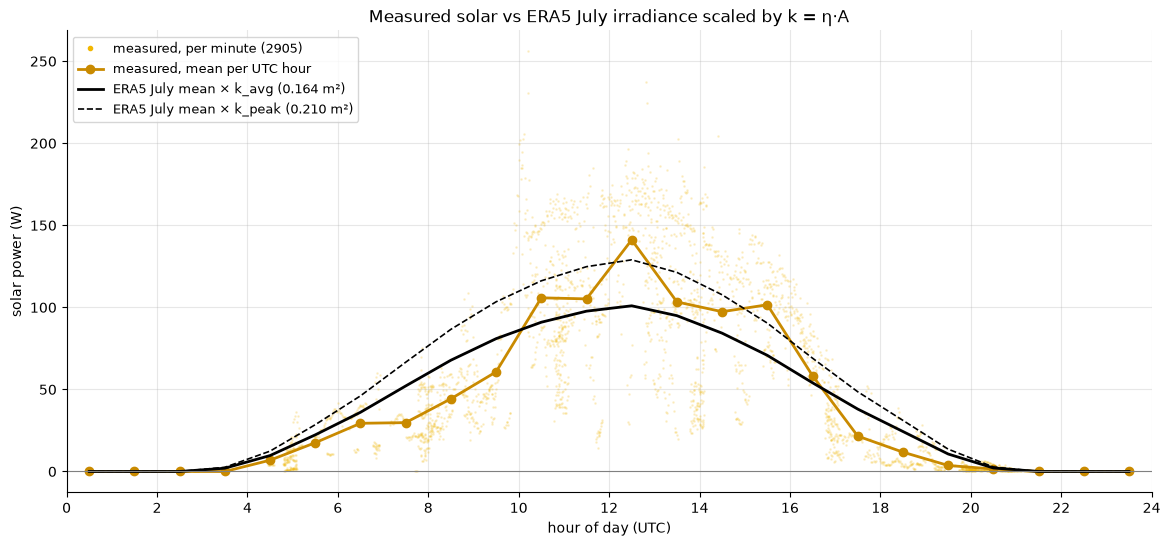

In [16]:
hrs = np.arange(24) + 0.5
fig, ax = plt.subplots()
ax.plot(sm.hour, sm.P_solar, ".", ms=2, alpha=0.15, color="#f2b701", label=f"measured, per minute ({len(sm)})")
ax.plot(hrs, P_by_hour, "o-", color="#c98a00", lw=2, label="measured, mean per UTC hour")
ax.plot(hrs, k_avg * G_by_hour, "-", color="k", lw=2, label=f"ERA5 July mean × k_avg ({k_avg:.3f} m²)")
ax.plot(hrs, k_peak * G_by_hour, "--", color="k", lw=1.2, label=f"ERA5 July mean × k_peak ({k_peak:.3f} m²)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 2))
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("solar power (W)")
ax.set_title("Measured solar vs ERA5 July irradiance scaled by k = η·A")
leg = ax.legend(loc="upper left", fontsize=9)
leg.legend_handles[0].set_markersize(6); leg.legend_handles[0].set_alpha(1)
plt.show()